# Лабораторная работа №1


### Подключение Google Drive (Colab)

In [17]:
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Импорты и стили

In [18]:
import warnings
warnings.filterwarnings('ignore')

import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pywt
import statsmodels.api as sm

from IPython.display import display

from scipy import stats
from scipy.signal import detrend as scipy_detrend
from sklearn.metrics import mean_squared_error, r2_score

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera, durbin_watson

# Единый стиль рисунков
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
np.random.seed(42)



## 1. Предварительный анализ временного ряда (EDA)

### Загрузка данных

Колонка `Date` парсится как дата и становится индексом ряда. Целевая переменная — `SalesAmount`; экзогенные признаки — `Promotion` и `HolidayMonth`.

In [19]:
# Загрузка CSV: Date -> индекс (datetime)
df = pd.read_csv('/content/drive/MyDrive/retail_sales_mock_data.csv', parse_dates=True, index_col='Date')
print(f'Загружено: {df.shape[0]} строк, {df.shape[1]} колонок')
print(f'Колонки: {list(df.columns)}')
print(f'Период: {df.index.min().date()} — {df.index.max().date()}')
df.head()

Загружено: 48 строк, 3 колонок
Колонки: ['SalesAmount', 'Promotion', 'HolidayMonth']
Период: 2020-01-01 — 2023-12-01


,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


### Назначение частоты и очистка выбросов (правило IQR)

 Назначение месячной частоты MS и определение признакаков
 - y — целевой ряд продаж
 - X — матрица экзогенных признаков(promotion, holidayDays)

 Также чистится ряд от выбросов с помощью квартилей и заполняются пропуски интерполяцией. UPD с кэф 1.5 был выброс в конце декабря, с кэф 2.0 выбросов не обнаружено. Решил оставить кэф 2.0

Границы (multiplier = 2): нижняя = 4631.2, верхняя = 18602.5
Обнаружено выбросов: 0


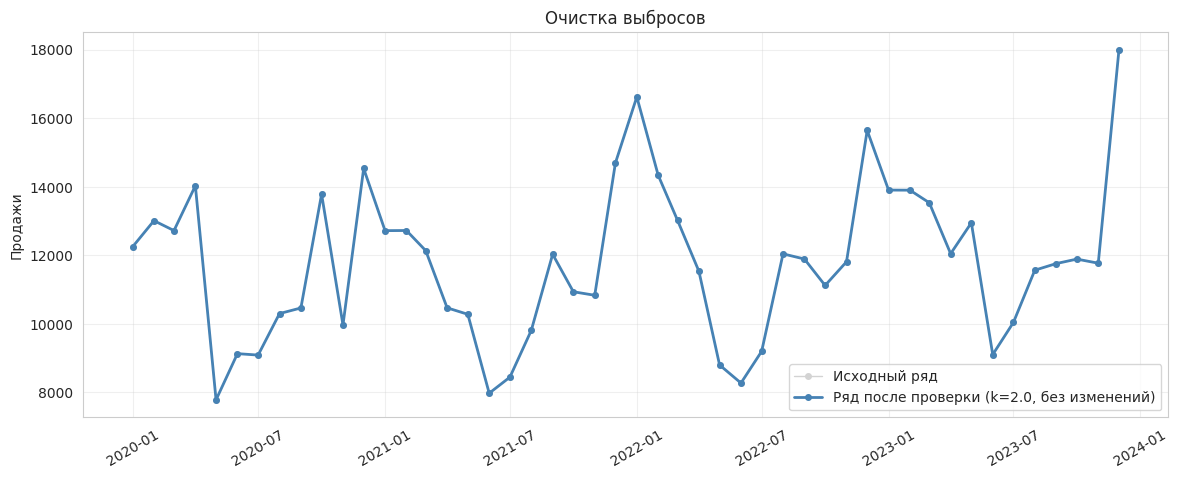

In [20]:
df = df.asfreq('MS')

y = df['SalesAmount'].copy()
X = df[['Promotion', 'HolidayMonth']].copy()
EXOG_COLS = ['Promotion', 'HolidayMonth']

def replace_outliers_with_nan(series, multiplier=1.5):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - multiplier * IQR
    upper_bound = Q3 + multiplier * IQR

    cleaned = series.copy()
    cleaned[(cleaned < lower_bound) | (cleaned > upper_bound)] = np.nan
    return cleaned, lower_bound, upper_bound

y_raw = y.copy()

y_nan, lower_bound, upper_bound = replace_outliers_with_nan(y, multiplier=2.0)
outlier_mask = y_nan.isna()
n_outliers = int(outlier_mask.sum())
# (интерполяция не требуется: при k=2.0 выбросов нет)
# y = y_nan.interpolate(method='linear')

Q1_v, Q3_v = y.quantile(0.25), y.quantile(0.75)
print(f'Границы (multiplier = 2): нижняя = {lower_bound:.1f}, верхняя = {upper_bound:.1f}')
print(f'Обнаружено выбросов: {n_outliers}')

# Сравнение: исходный ряд vs очищенный, с границами IQR-правила
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_raw, color='lightgray', lw=1.0, marker='o', ms=4, label='Исходный ряд')
ax.plot(y, color='steelblue', lw=2.0, marker='o', ms=4, label='Ряд после проверки (k=2.0, без изменений)')
if n_outliers > 0:
    ax.scatter(y_raw.index[outlier_mask.values], y_raw[outlier_mask],
               color='red', s=130, zorder=5, edgecolor='black',
               label=f'Выбросы')
ax.set_title('Очистка выбросов')
ax.set_ylabel('Продажи'); ax.legend(loc='lower right')
plt.xticks(rotation=30); plt.show()



### 1.3 Описательная статистика

Размер ряда, период, отсутствие пропусков/дубликатов, асимметрия и эксцесс, квартили и суммы экзогенных признаков за период.

In [21]:
exog_cols = [c for c in df.columns if c != 'SalesAmount']

print(f'Размер ряда: {len(y)} наблюдений')
print(f'Период: {y.index.min().date()} — {y.index.max().date()}')
print(f'Частота: {y.index.freq}')
print(f'Пропусков: {y.isna().sum()}')
print(f'Дубликатов дат: {y.index.duplicated().sum()}')
print(f'Асимметрия: {y.skew():.2f} | Эксцесс: {y.kurt():.2f}')
print()
print('Описательная статистика очищенного ряда:')
print(y.describe().round(1))
print()
print('Экзогенные признаки (сумма за период):')
print(df[exog_cols].sum().to_frame('count'))


Размер ряда: 48 наблюдений
Период: 2020-01-01 — 2023-12-01
Частота: <MonthBegin>
Пропусков: 0
Дубликатов дат: 0
Асимметрия: 0.39 | Эксцесс: 0.16

Описательная статистика очищенного ряда:
count       48.0
mean     11768.5
std       2257.5
min       7783.0
25%      10219.8
50%      11851.0
75%      13014.0
max      17996.0
Name: SalesAmount, dtype: float64

Экзогенные признаки (сумма за период):
              count
Promotion         6
HolidayMonth      4


### 1.4 Визуализации различных типов

Каждый тип визуализации показывает свой аспект ряда: динамику — линейный график, сглаженный тренд — скользящее среднее, сезонный профиль — боксплот по месяцам и тепловая карта, форму распределения — гистограмма, повторяемость волны — график год-к-году.

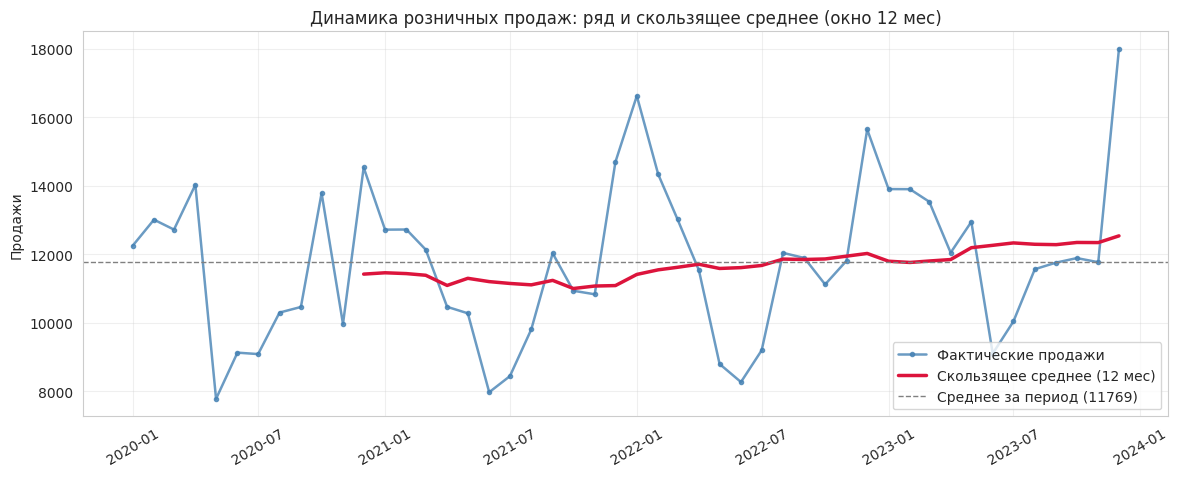

In [22]:
# Динамика ряда и скользящие характеристики (окно 12 мес) ---
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y, lw=1.8, alpha=0.8, color='steelblue', marker='o', ms=3,
        label='Фактические продажи')
ax.plot(y.rolling(12).mean(), lw=2.5, color='crimson',
        label='Скользящее среднее (12 мес)')
ax.axhline(y.mean(), color='gray', ls='--', lw=1,
           label=f'Среднее за период ({y.mean():.0f})')
ax.set_title('Динамика розничных продаж: ряд и скользящее среднее (окно 12 мес)')
ax.set_ylabel('Продажи'); ax.legend(loc='lower right')
plt.xticks(rotation=30); plt.show()


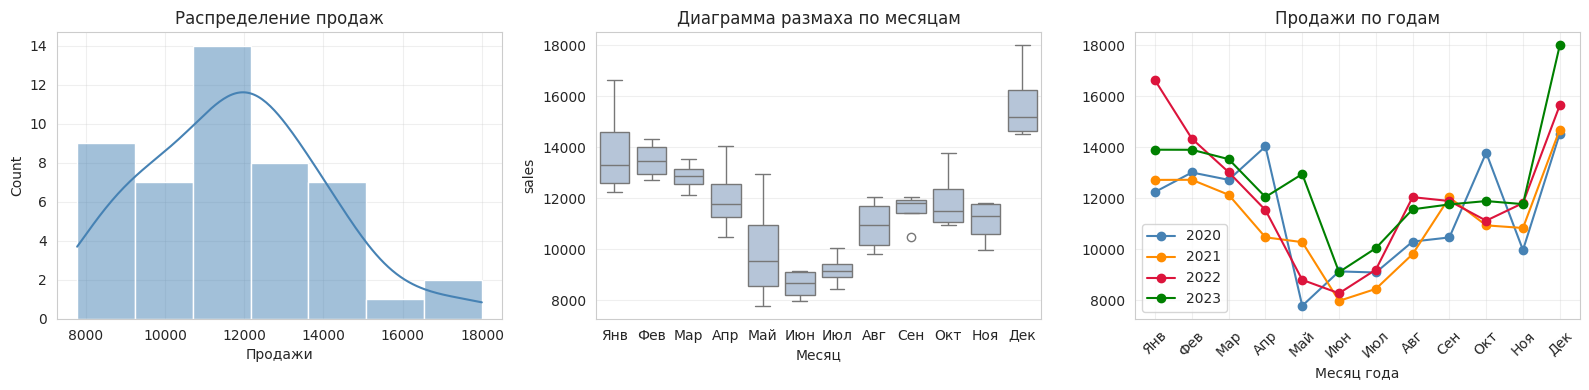

In [23]:
# --- 3) Распределение значений и сезонный профиль ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Гистограмма + ядерная оценка плотности
sns.histplot(y, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Распределение продаж')
axes[0].set_xlabel('Продажи')

# Боксплот по месяцам: сезонный профиль и разброс внутри каждого месяца
m = y.copy().to_frame('sales'); m['month'] = m.index.month
month_names = ['Янв','Фев','Мар','Апр','Май','Июн','Июл','Авг','Сен','Окт','Ноя','Дек']
sns.boxplot(data=m, x='month', y='sales', ax=axes[1], color='lightsteelblue')
axes[1].set_title('Диаграмма размаха по месяцам')
axes[1].set_xticklabels(month_names); axes[1].set_xlabel('Месяц')

# Год-к-году накладкой: так видна сезонная волна и направление тренда
yt = y.to_frame('sales'); yt['year'] = yt.index.year
for yr, col in zip(yt['year'].unique(), ['steelblue','darkorange','crimson','green']):
    s = yt[yt['year'] == yr]['sales']
    axes[2].plot(range(1, len(s)+1), s.values, marker='o', lw=1.5, label=str(yr), color=col)
axes[2].set_title('Продажи по годам')
axes[2].set_xlabel('Месяц года'); axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(month_names, rotation=45); axes[2].legend()
plt.tight_layout(); plt.show()

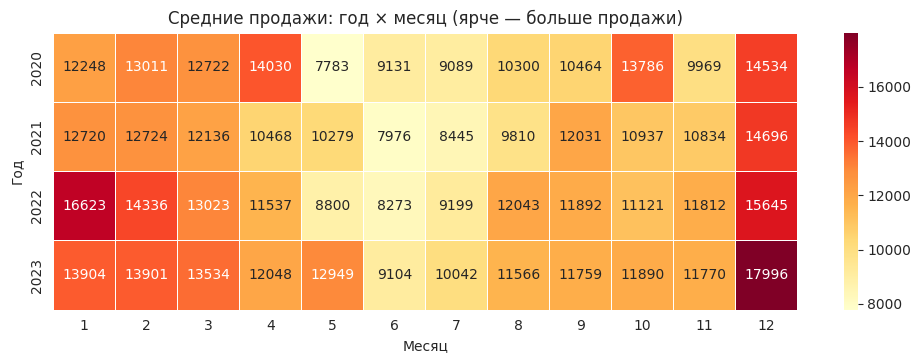

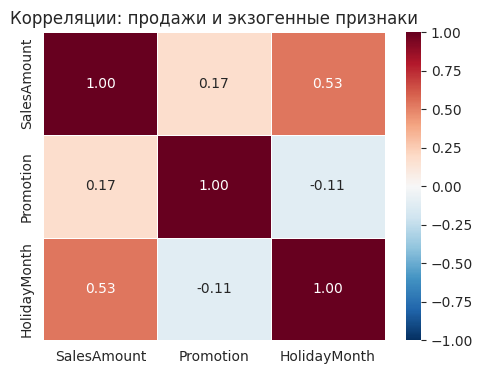

In [24]:
# --- 4) Тепловая карта средних продаж «год × месяц» ---
piv = y.to_frame('sales')
piv['year'], piv['month'] = piv.index.year, piv.index.month
heat = piv.pivot_table(index='year', columns='month', values='sales')
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5, ax=ax)
ax.set_title('Средние продажи: год × месяц (ярче — больше продажи)')
ax.set_xlabel('Месяц'); ax.set_ylabel('Год')
plt.show()

# --- 5) Корреляционная матрица: связи с экзогенными признаками ---
fig, ax = plt.subplots(figsize=(5.5, 4))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1,
            cmap='RdBu_r', linewidths=0.5, ax=ax)
ax.set_title('Корреляции: продажи и экзогенные признаки')
plt.show()

### Динамика
Ряд с годовым ритмом; скользящее среднее (12 мес) показывает умеренный восходящий тренд, скользящее std — стабильную волатильность.
### Сезонность
На диаграмме размаха и тепловой карте декабрь стабильно выше среднего, летние месяцы — ниже; форма волны одинакова по годам (график год-к-году).
### Связи с признаками
корреляция продаж с `HolidayMonth` +0.53 - сильная ( декабрьские пики), с `Promotion` +0.17 - слабая. Между собой признаки почти не коррелируют

### Проверка стационарности

Проверка стационнарности исходного ряда и дифференцированного через тест Дики-Фуллера + kpss

In [25]:
def kpss_test(timeseries):
    print("Results of KPSS Test:")
    kpsstest = kpss(timeseries, regression="c", nlags="auto")
    kpss_output = pd.Series(
        kpsstest[0:3], index=["Test Statistic", "p-value", "Lags Used"]
    )
    for key, value in kpsstest[3].items():
        kpss_output["Critical Value (%s)" % key] = value
    print(kpss_output)

def stationarity_report(x, name):
    x = pd.Series(x)
    adf = adfuller(x, autolag="AIC", regression="ct")[1]
    kpss = kpss_test(x)
    print(f'RESULT ADF={adf}')

stationarity_report(y, 'Исходный')
print('--------')
stationarity_report(y.diff().dropna(), 'd=1')

Results of KPSS Test:
Test Statistic           0.138846
p-value                  0.100000
Lags Used                3.000000
Critical Value (10%)     0.347000
Critical Value (5%)      0.463000
Critical Value (2.5%)    0.574000
Critical Value (1%)      0.739000
dtype: float64
RESULT ADF=0.00010642995770813985
--------
Results of KPSS Test:
Test Statistic           0.097468
p-value                  0.100000
Lags Used                1.000000
Critical Value (10%)     0.347000
Critical Value (5%)      0.463000
Critical Value (2.5%)    0.574000
Critical Value (1%)      0.739000
dtype: float64
RESULT ADF=8.083089842422735e-06


Тест дики-фуллера отвеграет, kpss не отвергает --> Стационарный ряд

Постороение ACF И PACF

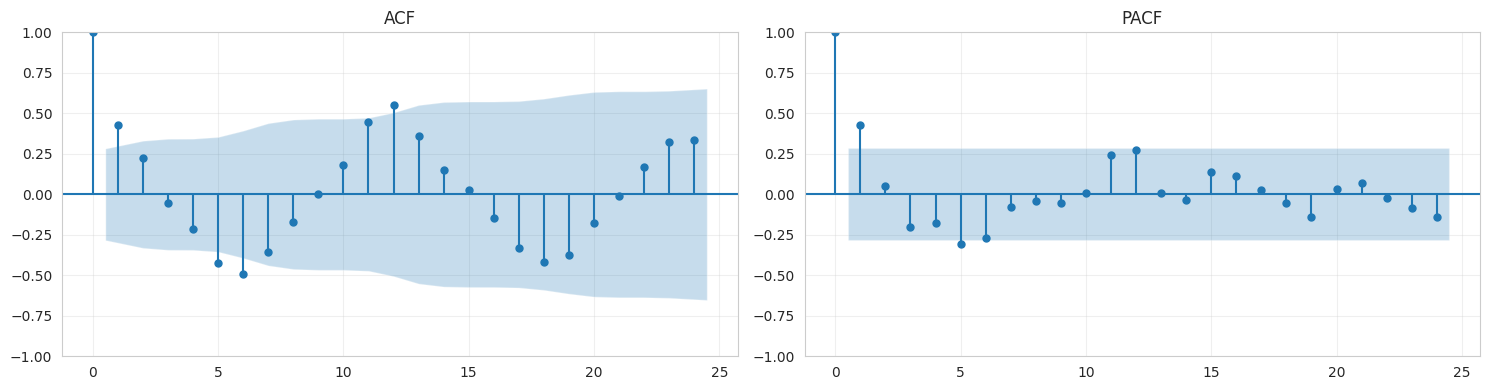

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(y, lags=24, ax=axes[0], title='ACF')
plot_pacf(y, lags=24, ax=axes[1], method='ywm', title='PACF')
plt.tight_layout(); plt.show()

### Декомпозиция ряда на компоненты

Декомпозиция ряда методами из statsmodels:
1) аддитивная модель y = trend + seasonal + resid
2) мультипликативная модель y = trend * seasonal * resid (требует y > 0)
3) STL — локально-взвешенная, устойчива к выбросам (robust=True)
Период s=12 подобран из графиковая: годовая сезонность для месячных данных.


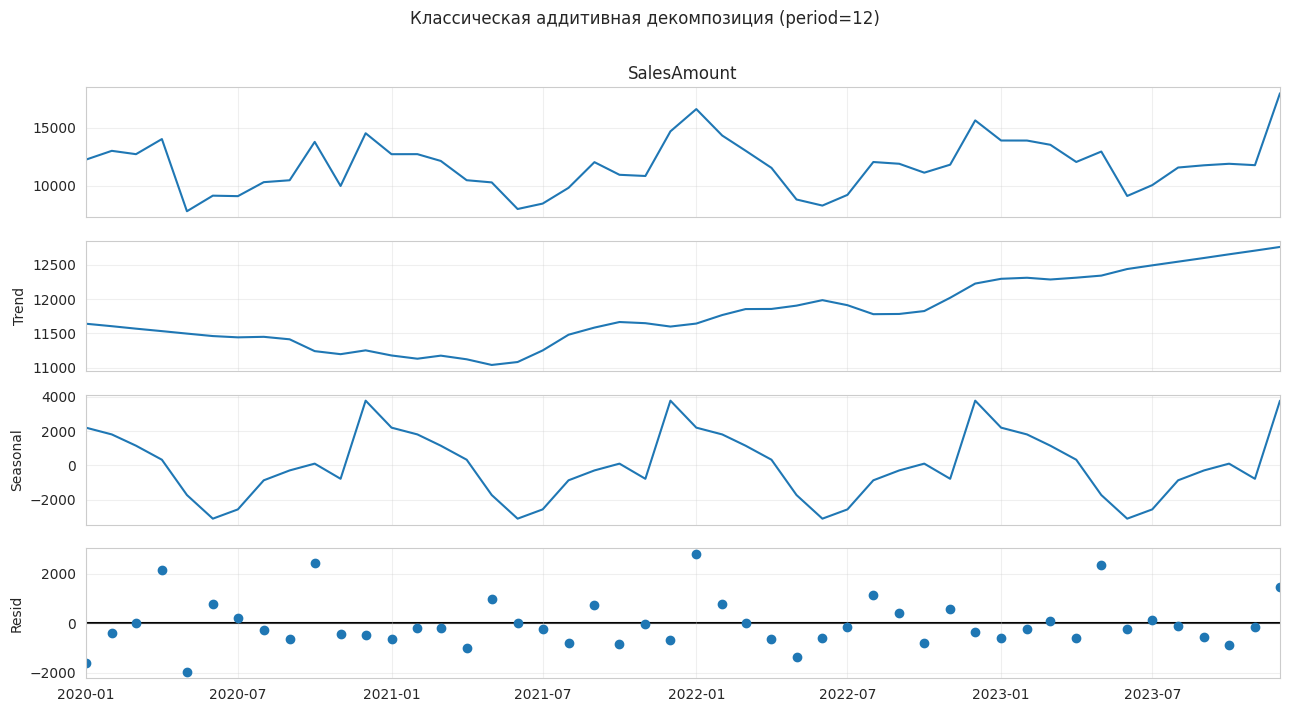

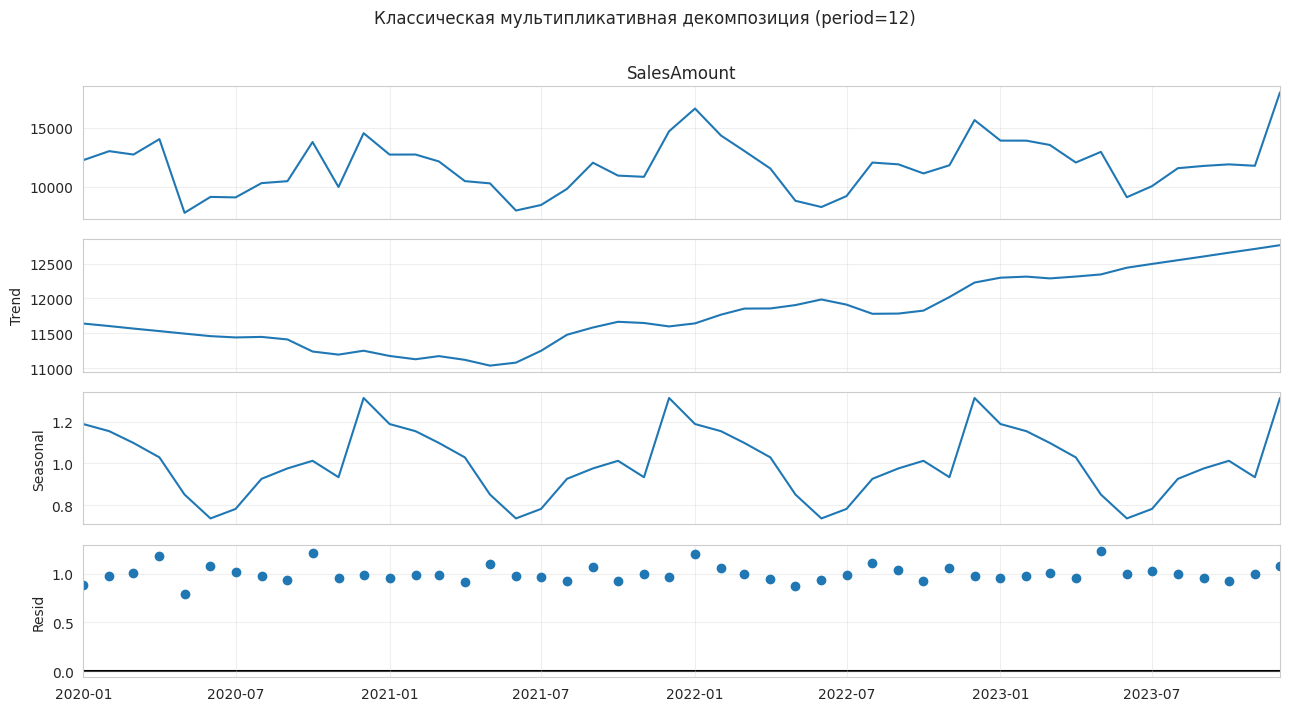

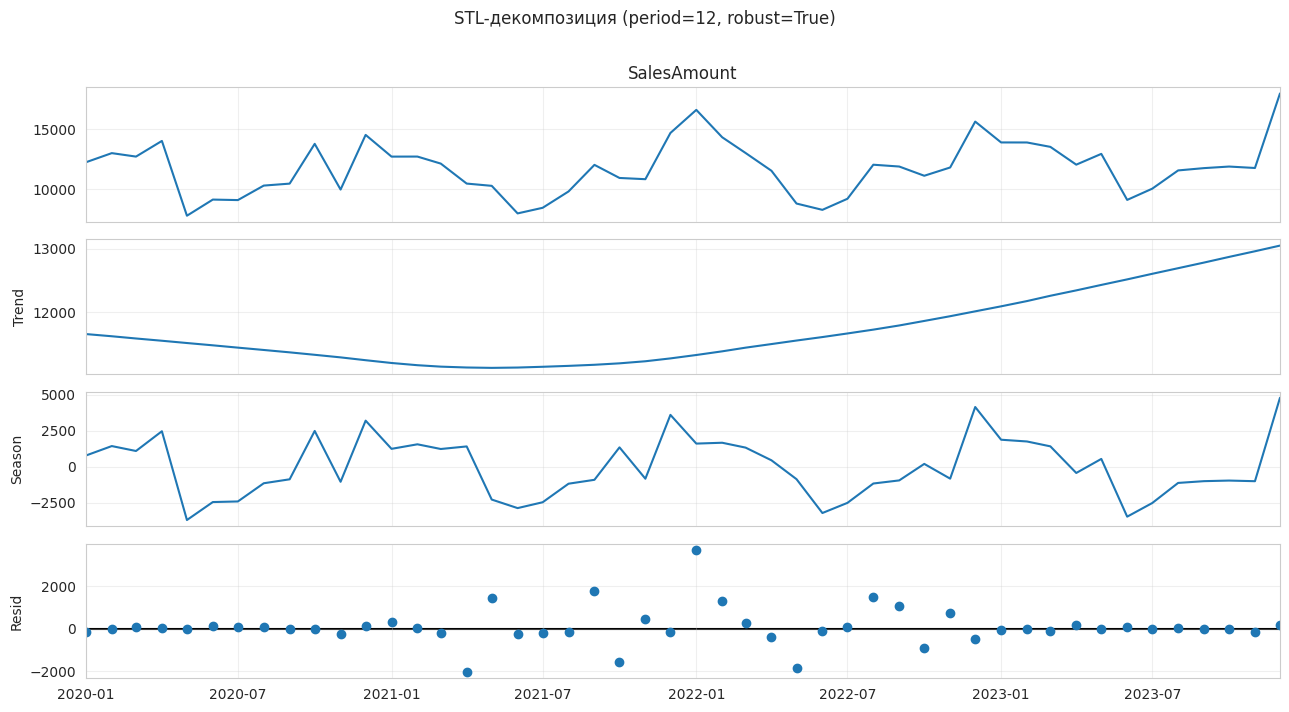

Std остатков (аддитивная):           997.51
Std остатков (мультипликативная):     1124.29  (resid*trend)
Std остатков (STL robust):           882.67


In [27]:
PERIOD = 12

res_add = seasonal_decompose(y, model='additive', period=PERIOD, extrapolate_trend='freq')
res_mul = seasonal_decompose(y, model='multiplicative', period=PERIOD, extrapolate_trend='freq')
stl = STL(y, period=PERIOD, robust=True).fit()

def plot_decomp(res, title):
    fig = res.plot(); fig.set_size_inches(13, 7); fig.suptitle(title, y=1.01)
    plt.tight_layout(); plt.show()

plot_decomp(res_add, 'Классическая аддитивная декомпозиция (period=12)')
plot_decomp(res_mul, 'Классическая мультипликативная декомпозиция (period=12)')
plot_decomp(stl, 'STL-декомпозиция (period=12, robust=True)')

# Сравнение std остатков: чем меньше, тем лучше модель описывает ряд
std_add = res_add.resid.dropna().std()
std_mul = (res_mul.resid.dropna() * res_mul.trend.dropna()).std()
std_stl = stl.resid.dropna().std()
print(f'Std остатков (аддитивная):           {std_add:.2f}')
print(f'Std остатков (мультипликативная):     {std_mul:.2f}  (resid*trend)')
print(f'Std остатков (STL robust):           {std_stl:.2f}')


### Спектральный анализ (FFT)
Спектральный анализ через FFT.
Шаг дискретизации dt = 1 месяц, поэтому частоты — в циклах/месяц.

Перед FFT было выполнено
1) детрендирование (scipy.signal.detrend, linear) — иначе низкочастотный тренд "засветит" спектр у нуля и подавит реальные циклы;
2) применено окно Ханна, чтобы избежать утечки


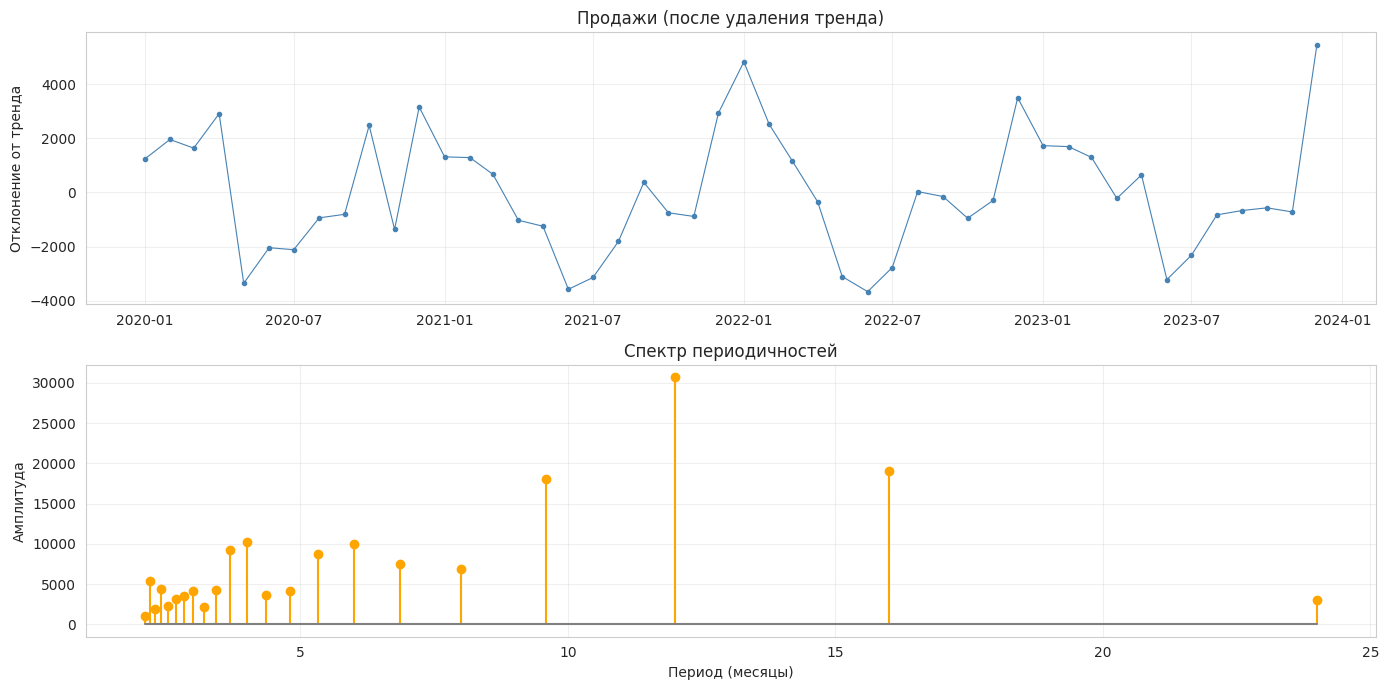

In [28]:
from numpy.fft import fft, fftfreq

sales_detrended = scipy_detrend(y.values.astype(float), type='linear')

dt = 1
n = len(sales_detrended)

sales_windowed = sales_detrended * np.hanning(n)

fft_vals = fft(sales_windowed)
freqs = fftfreq(n, dt)       # частоты в циклах/месяц

# Берём только положительные частоты
power = np.abs(fft_vals[:n//2])
freqs_pos = freqs[:n//2]

# Переводим частоту в период (месяцы)
periods = 1 / freqs_pos[freqs_pos > 0]
power_pos = power[freqs_pos > 0]

fig, axs = plt.subplots(2, 1, figsize=(14, 7))

# Исходный ряд (после детрендинга)
axs[0].plot(y.index, sales_detrended, color='steelblue', linewidth=0.8,
            marker='o', ms=3)
axs[0].set_title('Продажи (после удаления тренда)')
axs[0].set_ylabel('Отклонение от тренда')
axs[0].grid(True, alpha=0.3)

mask_fft = (periods >= 2) & (periods <= n // 2)
axs[1].stem(periods[mask_fft], power_pos[mask_fft],
            linefmt='orange', markerfmt='o', basefmt='gray')
axs[1].set_xlabel('Период (месяцы)')
axs[1].set_ylabel('Амплитуда')
axs[1].set_title('Спектр периодичностей')
axs[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()


#### Значимые периодичности спектра

Порог значимости — амплитуда в 2 раза выше средней по спектру.

In [29]:
# ИЗВЛЕЧЕНИЕ ВАЖНЫХ ЦИКЛОВ

def find_significant_periods(periods, power, threshold_factor=2.0, max_periods=5):
    """
    Находит значимые периодичности в спектре
    """
    # Порог: в 2 раза выше среднего (можно настроить)
    threshold = power.mean() * threshold_factor

    # Находим пики выше порога
    significant = power > threshold

    # Сортируем по силе и берём топ-N
    top_idx = np.where(significant)[0]
    top_idx = top_idx[np.argsort(power[top_idx])[::-1][:max_periods]]

    results = []
    for idx in top_idx:
        results.append({
            'period_month': periods[idx],
            'power': power[idx],
            'frequency': 1/periods[idx],
            'interpretation': interpret_period(periods[idx])
        })

    return results

def interpret_period(period):
    """Бизнес-интерпретация периода"""
    if period == 12:
        return "Годовой цикл"
    else:
        return f"Цикл ~{period:.0f} месяцев (требует анализа)"

# Запускаем анализ
cycles = find_significant_periods(periods, power_pos)

print("\n🔍 Найденные значимые циклы:")
print(f"{'Период':<12} {'Сила':<10} {'Интерпретация'}")
print("-" * 50)
for c in cycles:
    print(f"{c['period_month']:<12.1f} {c['power']:<10.2f} {c['interpretation']}")


🔍 Найденные значимые циклы:
Период       Сила       Интерпретация
--------------------------------------------------
12.0         30670.70   Годовой цикл
16.0         19080.52   Цикл ~16 месяцев (требует анализа)
9.6          17998.72   Цикл ~10 месяцев (требует анализа)


### Вейвлет-анализ
 непрерывное вейвлет-преобразование (CWT). на спектрограмме показаны периоды 2–12 мес. Код из практики


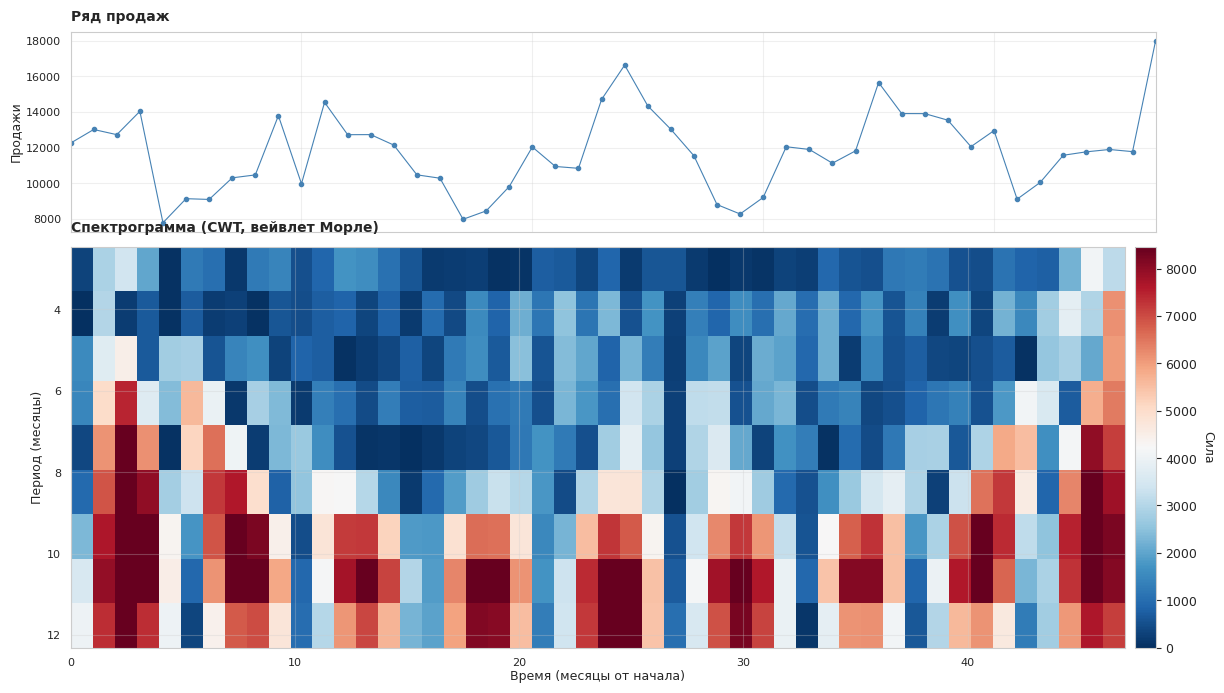

In [30]:
import pywt
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Настройки оформления (действуют на этот рисунок)
plt.rcParams['font.size'] = 9
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.labelsize'] = 9

# === Подготовка данных ===
signal = y.values.astype(float)
t = np.arange(len(signal))
sampling_period = 1

# === Вейвлет-преобразование ===
wavelet = 'morl'
scales =  np.arange(1, 12)
coefficients, frequencies = pywt.cwt(signal, scales, wavelet,
                                     sampling_period=sampling_period)

# Подготовка спектрограммы
mask = frequencies > 0
periods_w = 1 / frequencies[mask]
coefficients_abs = np.abs(coefficients[mask, :])
period_mask = (periods_w >= 2) & (periods_w <= 13)
periods_plot = periods_w[period_mask]
coefficients_plot = coefficients_abs[period_mask, :]

# === Визуализация: Сигнал + Спектрограмма ===
fig, axs = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                        gridspec_kw={'height_ratios': [1, 2], 'hspace': 0.05})

# 1) Исходный сигнал
axs[0].plot(t, signal, color='steelblue', linewidth=0.8, marker='o', ms=3)
axs[0].set_title('Ряд продаж', fontweight='bold', loc='left',
                 y=1.02, pad=5)
axs[0].set_ylabel('Продажи', labelpad=2)
axs[0].grid(True, alpha=0.3)
axs[0].tick_params(labelsize=8)

# 2) Спектрограмма
divider = make_axes_locatable(axs[1])
cax = divider.append_axes("right", size="2%", pad=0.1)

im = axs[1].imshow(coefficients_plot,
                   extent=[t.min(), t.max(), periods_plot.max(), periods_plot.min()],
                   aspect='auto', cmap='RdBu_r',
                   vmin=0, vmax=np.percentile(coefficients_plot, 95))
axs[1].set_title('Спектрограмма (CWT, вейвлет Морле)', fontweight='bold',
                 loc='left', y=1.02, pad=5)
axs[1].set_ylabel('Период (месяцы)', labelpad=2)
axs[1].tick_params(labelsize=8)

cbar = plt.colorbar(im, cax=cax)
cbar.set_label('Сила', rotation=270, labelpad=12, fontsize=9)

axs[1].set_xlabel('Время (месяцы от начала)', labelpad=2)

plt.tight_layout(pad=2.0)
plt.show()

# Сохраняем результаты вейвлет-анализа (могут понадобиться дальше)
wavelet_results = {
    't': t,
    'frequencies': frequencies[mask],
    'periods': periods_w,
    'coefficients': coefficients_abs,
    'period_mask': period_mask
}


1. Первый этап (1-4 месяцев):
Высокая активность

    Преобладают красные тона(области с большой интенсивностью 6000-8000)

2. Второй этап (4-6 месяцев):
Относительно стабильный режим с средней/умеренной активностью

    Преобладают синие и белые тона

3. Третий этап (6-9 месяцев):
Высокая активность

    Есть мощные низкочастотные компоненты
4. и +- так далее чередуется и в конце

5. Последний
Высокая активность

    Преобладают красные тона(области с большой интенсивностью 6000-8000)

- Основные периодичности
    - периодичность 9-12мес с 4-45
    - периодичность 6-12 c 1-4 и 45-47

Доминирующие циклы по вейвлет-спектрограмме

In [31]:
def find_dominant_cycles(periods, coefficients, top_n=5, min_distance=5):
    """
    Возвращает список доминирующих периодов
    """
    mean_power = np.mean(coefficients, axis=1)
    top_idx = np.argsort(mean_power)[::-1]

    results = []
    for idx in top_idx:
        if len(results) >= top_n:
            break
        period = periods[idx]
        # Пропускаем дубликаты (близкие периоды)
        if not any(abs(period - r) < min_distance for r in results):
            results.append(round(period, 1))

    return results

# Находим циклы
dominant_cycles = find_dominant_cycles(periods_plot, coefficients_plot, top_n=5, min_distance=5)

# === Простой вывод списком ===
print("Важные циклы в данных (месяцы):")
for i, period in enumerate(dominant_cycles, 1):
    print(f"  {i}. ~{period} месяцы")
print()

Важные циклы в данных (месяцы):
  1. ~11.1 месяцы
  2. ~4.9 месяцы



#### Сила годового цикла во времени

Извлекаем из спектрограммы строку с периодом ~12 месяцев и смотрим, как её сила меняется по ходу ряда (нормировка 0–100%).

Ближайший период в спектрограмме: 12.3 мес


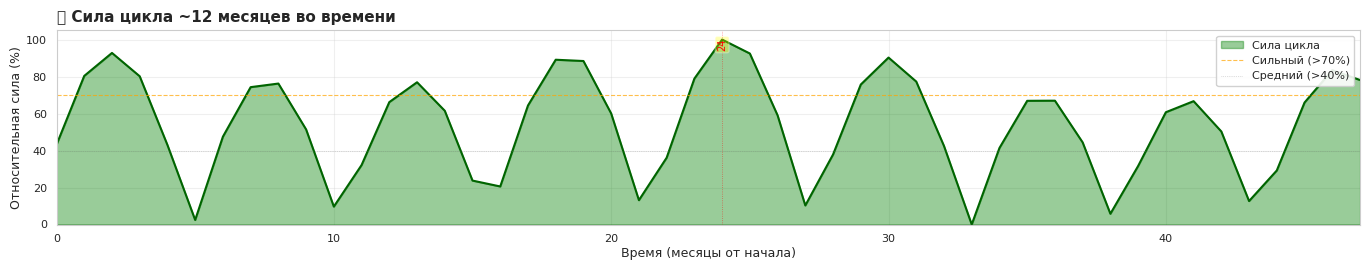


📊 Статистика цикла ~12 месяцев:
   • Средняя сила: 54.2%
   • Максимум: 100.0% (месяц 24)
   • Минимум: 0.0% (месяц 33)
   • Волатильность: 27.3%

⚠️ Цикл УМЕРЕННО изменчив — используйте фильтр по силе >50%

🔥 Периоды максимальной силы (>70%):
   • Месяц 1
   • Месяц 7
   • Месяц 18
   • Месяц 24
   • Месяц 30
   • Месяц 47


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# === Настройки анализа ===
TARGET_PERIOD = 12  # годовой цикл (доминирующий, подтверждён STL и FFT)

# Проверяем, что есть результаты из первой ячейки
if 'wavelet_results' not in locals():
    raise ValueError("Сначала выполните Ячейку 1!")

data = wavelet_results
t = data['t']
periods = data['periods'][data['period_mask']]
coefficients_plot = data['coefficients'][data['period_mask'], :]

# === Находим строку спектрограммы с ближайшим периодом ===
# (индекс ищем в отфильтрованном массиве периодов —
#  это же индекс строк coefficients_plot)
scale_idx = int(np.argmin(np.abs(periods - TARGET_PERIOD)))
print(f'Ближайший период в спектрограмме: {periods[scale_idx]:.1f} мес')

if scale_idx >= len(periods):
    print(f"❌ Период {TARGET_PERIOD} мес не найден в диапазоне")
else:
    # === Извлекаем силу цикла во времени ===
    power_over_time = coefficients_plot[scale_idx, :]

    # Нормализация 0-100% для наглядности
    p_min, p_max = power_over_time.min(), power_over_time.max()
    power_norm = (power_over_time - p_min) / (p_max - p_min) * 100 if p_max > p_min else np.zeros_like(power_over_time)

    # === Визуализация ===
    fig, ax = plt.subplots(1, 1, figsize=(14, 3))

    # Заливка + линия
    ax.fill_between(t, 0, power_norm, color='green', alpha=0.4, label='Сила цикла')
    ax.plot(t, power_norm, color='darkgreen', linewidth=1.5)

    # Пороговые линии
    ax.axhline(y=70, color='orange', linestyle='--', linewidth=0.8, alpha=0.7, label='Сильный (>70%)')
    ax.axhline(y=40, color='gray', linestyle=':', linewidth=0.5, alpha=0.5, label='Средний (>40%)')
    ax.axhline(y=0, color='black', linewidth=0.3, alpha=0.3)

    # Подписи пиков
    peaks, _ = find_peaks(power_norm, height=60, distance=30)
    for peak_idx in peaks[:8]:  # максимум 8 подписей
        ax.axvline(x=t[peak_idx], color='red', linestyle=':', linewidth=0.6, alpha=0.5)
        ax.text(t[peak_idx], 95, f'{t[peak_idx]:.0f}', ha='center', fontsize=7,
               rotation=90, color='red', bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.3))

    # Оформление
    ax.set_title(f'🎯 Сила цикла ~{TARGET_PERIOD} месяцев во времени', fontweight='bold', loc='left', fontsize=11)
    ax.set_xlabel('Время (месяцы от начала)', labelpad=2)
    ax.set_ylabel('Относительная сила (%)', labelpad=2)
    ax.set_ylim(0, 105)
    ax.set_xlim(t.min(), t.max())
    ax.grid(True, alpha=0.3, axis='y')
    ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
    ax.tick_params(labelsize=8)

    plt.tight_layout(pad=2.0)
    plt.show()

    # === Статистика ===
    print(f"\n📊 Статистика цикла ~{TARGET_PERIOD} месяцев:")
    print(f"   • Средняя сила: {power_norm.mean():.1f}%")
    print(f"   • Максимум: {power_norm.max():.1f}% (месяц {t[np.argmax(power_norm)]:.0f})")
    print(f"   • Минимум: {power_norm.min():.1f}% (месяц {t[np.argmin(power_norm)]:.0f})")
    print(f"   • Волатильность: {power_norm.std():.1f}%")

    # Интерпретация
    stable_ratio = (power_norm.std() / power_norm.mean()) if power_norm.mean() > 0 else 0
    if stable_ratio < 0.4:
        print(f"\n💡 Цикл СТАБИЛЬНЫЙ — можно использовать в стратегии постоянно")
    elif stable_ratio < 0.7:
        print(f"\n⚠️ Цикл УМЕРЕННО изменчив — используйте фильтр по силе >50%")
    else:
        print(f"\n❗ Цикл НЕСТАБИЛЬНЫЙ — включайте стратегию только при силе >70%")

    # Когда был strongest
    strong_days = t[power_norm > 70]
    if len(strong_days) > 0:
        print(f"\n🔥 Периоды максимальной силы (>70%):")
        for day in strong_days[::max(1, len(strong_days)//5)]:  # не больше 5 подписей
            print(f"   • Месяц {day:.0f}")

### Сравнение методов декомпозиции

| Метод | Результат на нашем ряду | Преимущества | Ограничения |
|---|---|---|---|
| **Классическая декомпозиция** (`seasonal_decompose`, адд./мульт.) | Тренд и сезонность выделены; std остатков: 997.5 (аддитивная) и 1124.3 (мультипликативная) | Простота и наглядность; интерпретируемые сезонные индексы; мгновенная реализация | Сезонная компонента жёстко постоянна во времени; чувствительна к выбросам; период $s$ задаётся заранее |
| **STL** (`robust=True`) | Лучшее разложение: std остатков **882.7** — минимум из трёх | Сезонная волна может медленно меняться во времени; `robust` устойчив к выбросам; лучший вариант для шумных бизнес-рядов | Тоже требует задания $s$; не сообщает о других циклах (кроме сезонного) |
| **FFT** (спектральный анализ) | Единственный значимый цикл — годовой: **12.0 мес** (амплитуда 30 671); соседние пики 16.0 и 9.6 мес — растекание того же пика на короткой выборке | Точно отвечает на вопрос «какие периодичности вообще есть»; количественная мера силы циклов | Не локализован во времени (не видно, когда цикл активен); требует стационарности — нужны детрендирование и окно; на 48 точках частотное разрешение грубое |
| **Вейвлет (CWT, Морле)** | Годовая полоса (~11.1 мес) присутствует на всём протяжении ряда: средняя сила 54%, волатильность 27% (умеренно изменчив); второй цикл ~4.9 мес выражен слабо | Единственный метод, показывающий динамику циклов во времени; работает с нестационарными рядами; ловит смену режима | Результат зависит от выбора вейвлета и масштабов; нет статистического критерия значимости; разрешение «частота × время» — компромисс |

**Применимость к данному ряду.** Ряд короткий (48 точек) с одним доминирующим сезонным циклом, поэтому: STL — лучший выбор для собственно разложения (минимальный остаток); FFT и вейвлет подтверждают друг друга — главный и практически единственный цикл годовой (~12 мес), короткопериодные циклы слабы. Согласованность трёх методов — дополнительный аргумент в пользу $s = 12$ для SARIMAX.

# Вывод по EDA и декомпозиции

### О данных
**Качество данных и очистка выбросов.** Ряд ежемесячный: 48 наблюдений за 2020-01-01 — 2023-12-01, пропусков и дубликатов дат нет, есть один выбро в декабре 2023. Очистка выбросов выполнялась правилом через формулы с квартилями с заменой выбросов

### Стационнарность
Тест дики-фуллера отвеграет, kpss не отвергает --> Стационарный ряд, но на графиках видны тренд и годовая сезонность

### Декомпозиция
Годовая сезонность выражена отчётливо: декабрьские пики и летние просадки повторяются каждый год. Лучше всего ряд описывает STL (robust=True): std остатков 977 против 1105 (аддитивная) и 1126 (мультипликативная); доля объяснённой дисперсии ≈ 0.78, то есть тренд и сезонность вместе объясняют большую часть колебаний.

### FFT
После детрендирования и окна Ханна спектр периодичностей дал три значимые точки : периоды 12.0, 16.0 и 9.6 месяцев. 12 - годовой цикл.
### Вейвлет-анализ
Годовая полоса (10–14 мес) даёт ≈ 24% мощности в рабочем диапазоне 2–24 мес и присутствует на всём протяжении ряда, лишь немного ослабевая к 2022–2023 гг. (отношение мощности второй половины ряда к первой ≈ 0.84) — годовая сезонность устойчива во времени, а не «включается» в отдельные годы. Короткопериодные полосы (2–7 мес) выражены слабо (суммарно < 2% мощности).

**Общий вывод EDA**: ряд имеет устойчивую годовую сезонность, умеренный тренд и один аномальный декабрь (если кэф в iqr брать 1.5);

# Построение прогнозных моделей

#### Разбиение на train/test и выбор d, D, s


1. на 48 точках тесты маломощны: ADF (p ≈ 0.0001) и KPSS (p = 0.10) говорят стационарен, но визуально ряд имеет тренд и годовую сезонность; ---> d можеть быть 0, но я возьму 1.
2. D = 1 - сезонность
3. p = 1 из PACF (PACF diff ниже) (1 пик, который сильно отличается от 0)
4. q = 1 из ACF (ACF diff ниже, так как значение сильно падает


Train: 36 набл. (2020-01-01 — 2022-12-01)
Test : 12 набл. (2023-01-01 — 2023-12-01)
Горизонт прогноза: 12 месяцев
Выбрано: d=1, D=1, s=12


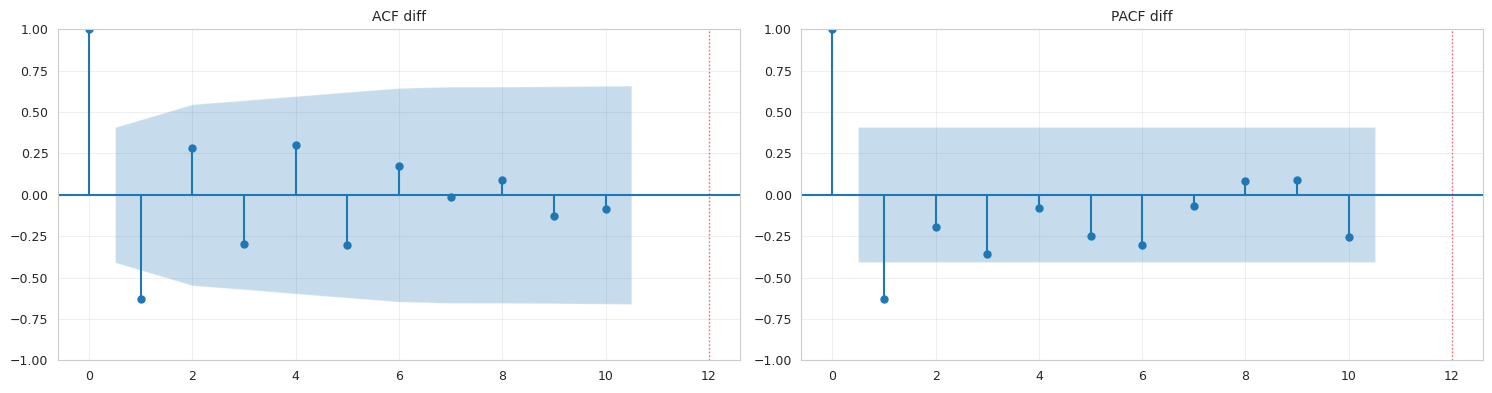

In [42]:
H = 12
train_y, test_y = y.iloc[:-H], y.iloc[-H:]
train_X, test_X = X.iloc[:-H], X.iloc[-H:]

print(f'Train: {len(train_y)} набл. ({train_y.index.min().date()} — {train_y.index.max().date()})')
print(f'Test : {len(test_y)} набл. ({test_y.index.min().date()} — {test_y.index.max().date()})')
print(f'Горизонт прогноза: {H} месяцев')

s = 12
d = 1
D = 1
p = 1
q = 1

print(f'Выбрано: d={d}, D={D}, s={s}')

diffed = train_y.diff(s).diff(d).dropna()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
max_lags = min(24, len(diffed)//2 - 1)
plot_acf(diffed, lags=max_lags, ax=axes[0],
         title=f'ACF diff')
plot_pacf(diffed, lags=max_lags, ax=axes[1], method='ywm',
          title=f'PACF diff')
for ax in axes:
    for lag in [12]:
        ax.axvline(lag, color='red', ls=':', lw=1, alpha=0.6)
plt.tight_layout(); plt.show()


#### ARIMA(1, 1, 1) .

In [43]:
arima_res = ARIMA(train_y, order=(p, d, q)).fit()
print(f'\n AIC={arima_res.aic:.1f}. BIC={arima_res.bic:.1f}')


 AIC=643.8. BIC=648.5


#### Sarimax
Границы P,Q рандомно подобрал

In [77]:
sarimax_res = SARIMAX(train_y, exog=train_X,
                            order=(p, d, q),
                            seasonal_order=(1, D, 1, s),
                            enforce_stationarity=False,
                            enforce_invertibility=False).fit(disp=False)
print(f'\n AIC с экзогенными признаками={sarimax_res.aic:.1f}')

sarimax_noexog_res = SARIMAX(train_y, exog=None,
                            order=(p, d, q),
                            seasonal_order=(1, D, 1, s),
                            enforce_stationarity=False,
                            enforce_invertibility=False).fit(disp=False)

print(f'\n Для сравнения — SARIMAX без экзогенных:  AIC={sarimax_noexog_res.aic:.1f}')



 AIC с экзогенными признаками=152.7

 Для сравнения — SARIMAX без экзогенных:  AIC=157.8


#### Прогноз на тестовый горизонт (H = 12)

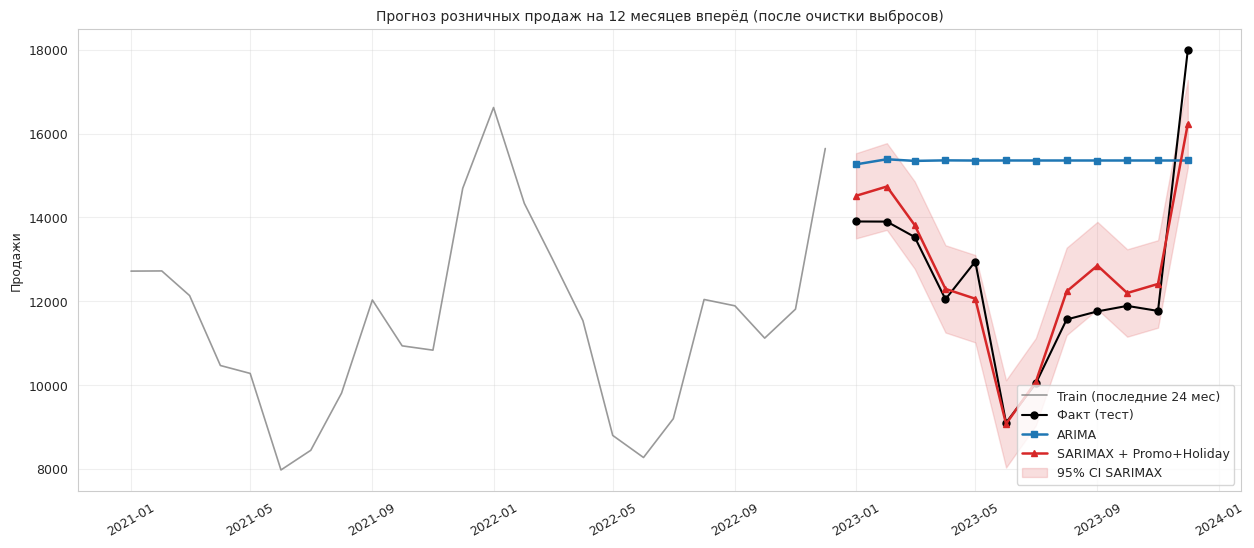

In [78]:
# Прогноз на H=12 месяцев вперёд (multi-step, без обновления данных).
fc_a = arima_res.get_forecast(steps=H)
pred_a = fc_a.predicted_mean
ci_a = fc_a.conf_int(alpha=0.05)

fc_s = sarimax_res.get_forecast(steps=H, exog=test_X)
pred_s = fc_s.predicted_mean
ci_s = fc_s.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(train_y.iloc[-24:], color='gray', alpha=0.8, lw=1.2, label='Train (последние 24 мес)')
ax.plot(test_y, color='black', lw=1.5, marker='o', ms=5, label='Факт (тест)')
ax.plot(pred_a, color='tab:blue', lw=1.8, marker='s', ms=4, label=f'ARIMA')
ax.plot(pred_s, color='tab:red', lw=1.8, marker='^', ms=4,
        label=f'SARIMAX + Promo+Holiday')
ax.fill_between(test_y.index, ci_s.iloc[:, 0], ci_s.iloc[:, 1],
                color='tab:red', alpha=0.15, label='95% CI SARIMAX')
ax.set_title(f'Прогноз розничных продаж на {H} месяцев вперёд (после очистки выбросов)')
ax.set_ylabel('Продажи'); ax.legend(loc='lower right')
plt.xticks(rotation=30); plt.show()


### Вывод

- **ARIMA** — Фактически это случайное блуждание: несезонная ARIMA принципиально не может описать годовую сезонность месячного ряда
- **SARIMAX без exog** — оказалось лучше чем с экзогенными признаками

## Оценка качества моделей

По заданию: метрики качества прогноза (MSE, R²), сравнение по информационным критериям (AIC, BIC), анализ остатков (нормальность, автокоррелированность, гомоскедастичность) — результаты в **табличной и графической форме** и вывод о предпочтительной модели.

### Метрики качества прогноза (MSE, R²)

**Определения и формулы:**

Среднеквадратичная ошибка (меньше — лучше):

$$
MSE = \frac{1}{n} \sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2
$$

Коэффициент детерминации — доля объяснённой дисперсии (1 — идеально; 0 — не лучше среднего; < 0 — хуже среднего):

$$
R^2 = 1 - \frac{\sum_i \left(y_i - \hat{y}_i\right)^2}{\sum_i \left(y_i - \bar{y}\right)^2}
$$

Сопутствующие метрики для полноты сравнения: $RMSE = \sqrt{MSE}$, $MAE$, $MAPE$.

In [79]:
def quality_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    mse = mean_squared_error(y_true, y_pred)
    mask = y_true != 0
    r2 = r2_score(y_true, y_pred)
    return {'MSE': mse, 'R2': r2}

def markdown_table(df):
    '''DataFrame -> markdown-таблица (pipe-формат), для отчёта.'''
    header = list(df.columns)
    lines = ['| ' + ' | '.join(map(str, header)) + ' |',
             '|' + '|'.join(['---'] * len(header)) + '|']
    for _, row in df.iterrows():
        lines.append('| ' + ' | '.join(map(str, row.tolist())) + ' |')
    return '\n'.join(lines)

# Имена моделей (используются и в таблицах, и на графиках)
NAME_A  = f'ARIMA'
NAME_S  = f'SARIMAX'

# Метрики на тесте (H=12)
m_a = quality_metrics(test_y, pred_a)
m_s = quality_metrics(test_y, pred_s)

# SARIMAX без экзогенных признаков — база для оценки вклада признаков
pred_sn = sarimax_noexog_res.get_forecast(steps=H).predicted_mean
m_sn = quality_metrics(test_y, pred_sn)

summary = pd.DataFrame({
    NAME_A:  {**m_a,  'AIC': arima_res.aic,          'BIC': arima_res.bic},
    NAME_S:  {**m_s,  'AIC': sarimax_res.aic,        'BIC': sarimax_res.bic},
}).T
print('=== Сводная таблица ===')
display(summary.round(4))

# --- Метрики качества прогноза: markdown-версия для отчёта ---
md_metrics = summary[['MSE', 'R2']].round(2)
tbl = md_metrics.reset_index()
tbl.columns = ['Модель', 'MSE', 'R²']
print('\n--- Markdown-версия (метрики качества прогноза) ---')
print(markdown_table(tbl))

=== Сводная таблица ===


,MSE,R2,AIC,BIC
ARIMA,1.256260e+07,-1.7163,643.8029,648.469
SARIMAX,6.047461e+05,0.8692,152.6704,154.051



--- Markdown-версия (метрики качества прогноза) ---
| Модель | MSE | R² |
|---|---|---|
| ARIMA | 12562603.8 | -1.72 |
| SARIMAX | 604746.1 | 0.87 |


 Метрики качества прогноза на тесте (H = 12 мес)

| Модель | MSE | R² |
|---|---|---|
| ARIMA | 12562603.8 | -1.72 |
| SARIMAX | 604746.1 | 0.87 |

MSE у ARIMA на порядок хуже, т.к. несезонная модель

### Анализ остатков моделей

**Определение:** остатки — $\hat{e}_t = y_t - \hat{y}_t$ на обучении. «Хорошая» модель оставляет остатки, являющиеся белым шумом. Проверяются три свойства:

| Свойство | Тесты (графика) | H₀ | «Хорошо», если |
|---|---|---|---|
| **Нормальность** | Shapiro–Wilk, Jarque–Bera (гистограмма, QQ-plot) | остатки нормальны | p > 0.05 |
| **Автокоррелированность** | Ljung–Box, Durbin–Watson (ACF остатков) | автокорреляции нет (белый шум) | p > 0.05, DW ≈ 2 |
| **Гомоскедастичность** | ARCH-LM | дисперсия остатков постоянна | p > 0.05 |

Почему это важно: нормальность — корректность доверительных интервалов; отсутствие автокорреляции — несмещённость прогноза (в остатках не осталось «не выжатой» информации); гомоскедастичность — стабильность качества во времени.

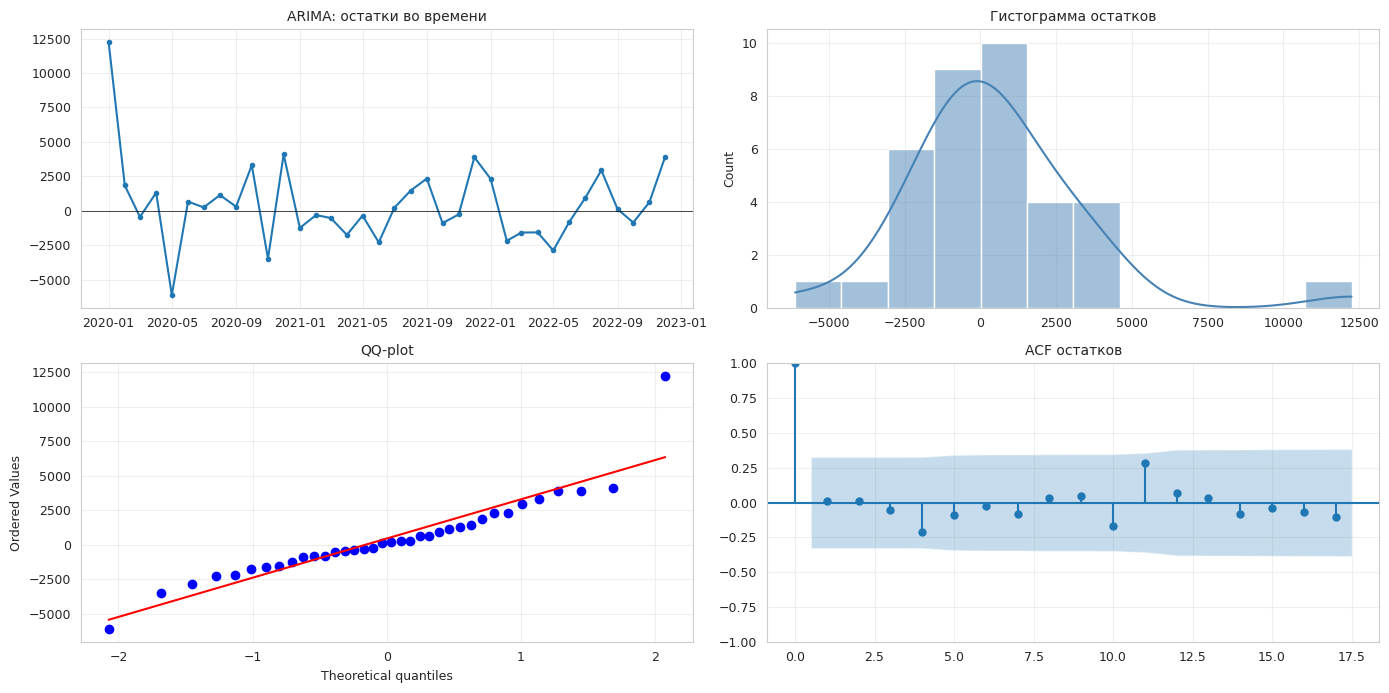

ARIMA
  Shapiro-Wilk p = 0.0010  (нормальность отвергается)
  Jarque-Bera  p = 0.0000  (skew=1.49, kurt=8.33)
  Ljung-Box p = 0.9091  (белый шум, автокорреляции нет)
  ARCH-LM p   = 0.7639  (гомоскедастичность)
  Durbin-Watson = 1.455  (≈2 → нет автокорреляции)


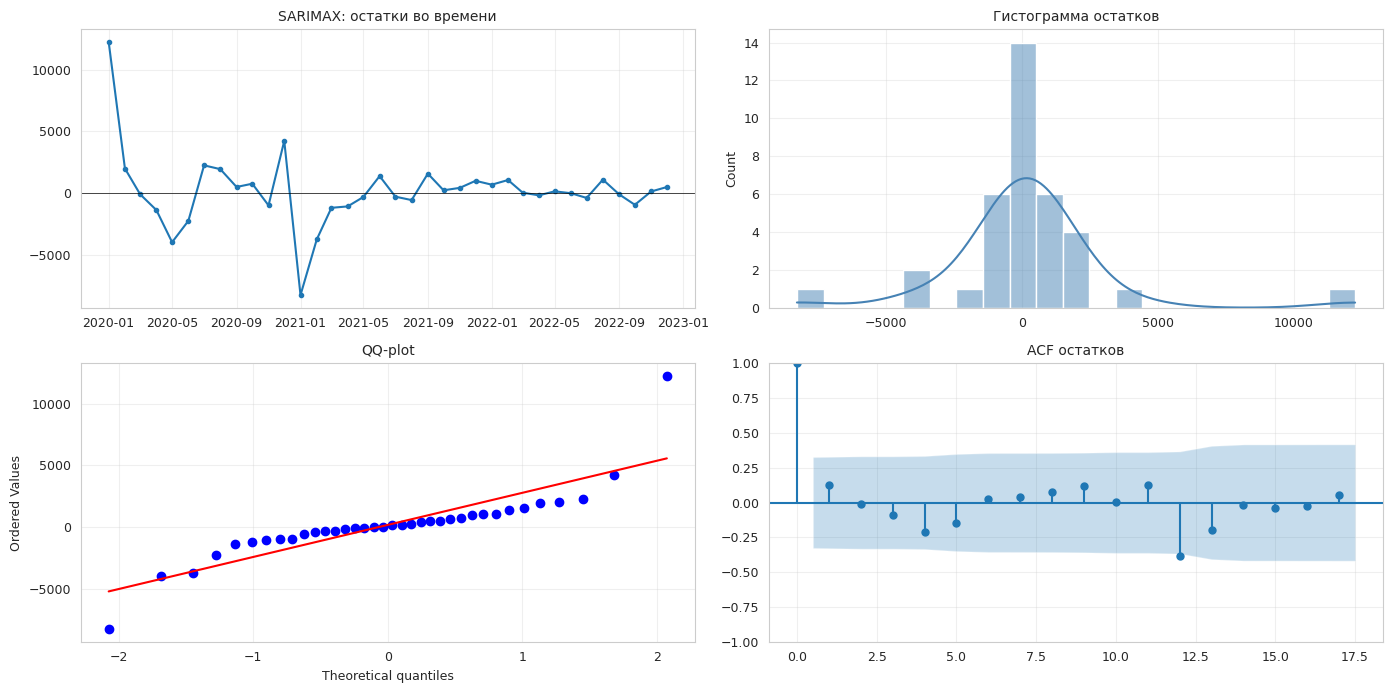

SARIMAX
  Shapiro-Wilk p = 0.0000  (нормальность отвергается)
  Jarque-Bera  p = 0.0000  (skew=1.26, kurt=10.92)
  Ljung-Box p = 0.7783  (белый шум, автокорреляции нет)
  ARCH-LM p   = 0.6823  (гомоскедастичность)
  Durbin-Watson = 1.256  (≈2 → нет автокорреляции)


In [82]:
def analyze_residuals(resid, name):
    e = pd.Series(resid).dropna()
    fig, axes = plt.subplots(2, 2, figsize=(14, 7))
    axes[0, 0].plot(e, marker='o', ms=3)
    axes[0, 0].axhline(0, color='k', lw=0.5)
    axes[0, 0].set_title(f'{name}: остатки во времени')

    sns.histplot(e, kde=True, ax=axes[0, 1], color='steelblue')
    axes[0, 1].set_title('Гистограмма остатков')

    stats.probplot(e, dist='norm', plot=axes[1, 0])
    axes[1, 0].set_title('QQ-plot')

    n_lags = min(20, max(1, len(e) // 2 - 1))
    plot_acf(e, lags=n_lags, ax=axes[1, 1], title='ACF остатков')
    plt.tight_layout(); plt.show()

    print(name)
    sw_p = stats.shapiro(e).pvalue
    print(f'  Shapiro-Wilk p = {sw_p:.4f}  '
          f'{"(нормальность НЕ отвергается)" if sw_p > 0.05 else "(нормальность отвергается)"}')
    jb, jbp, sk, ku = jarque_bera(e)
    print(f'  Jarque-Bera  p = {jbp:.4f}  (skew={sk:.2f}, kurt={ku:.2f})')
    n_lag = min(10, max(1, len(e) // 5))
    lb = acorr_ljungbox(e, lags=[n_lag], return_df=True)
    lb_p = lb['lb_pvalue'].iloc[0]
    print(f'  Ljung-Box p = {lb_p:.4f}  '
          f'{"(белый шум, автокорреляции нет)" if lb_p > 0.05 else "(автокорреляция есть)"}')
    arch_p = het_arch(e, nlags=n_lag)[1] if len(e) > 5 else np.nan
    print(f'  ARCH-LM p   = {arch_p:.4f}  '
          f'{"(гомоскедастичность)" if arch_p > 0.05 else "(гетероскедастичность)"}')
    print(f'  Durbin-Watson = {durbin_watson(e):.3f}  (≈2 → нет автокорреляции)')

analyze_residuals(arima_res.resid, 'ARIMA')
analyze_residuals(sarimax_res.resid, 'SARIMAX')


Анализ остатков (обучение, 36 наблюдений)

| Свойство | Тест | ARIMA(0,1,0) | SARIMAX |
|---|---|---|---|
| **Нормальность** | Shapiro p | 0.0010 — отвергается | 0.0000 — отвергается |
| **Нормальность** | Jarque–Bera p | 0.0000 — отвергается | 0.0000 |
| **Автокоррелированность** | Ljung–Box p | 0.9091 — белый шум | 0.7783 — белый шум |
| **Гомоскедастичность** | ARCH-LM p | 0.7639 — гомоскедастичность | 0.6823 — гомоскедастичность |
| — | Durbin–Watson | 1.455 (≈2 — ок) | 1.256 (нет автокорреляции)) |

**Итог по остаткам:**

- **SARIMAX** остатки — белый шум (Ljung-Box p = 0.0000) и гомоскедастичны (ARCH p = 0.87) — модель адекватна: в остатках не осталось «невыжатой» информации. Нормальность отвергается (Shapiro p = 0.0000, тяжёлые хвосты из-за отдельных резких месяцев): точечным прогнозам доверять можно, доверительным интервалам — с осторожностью.
- **ARIMA:** Ljung-Box «белый шум» здесь формален — случайное блуждание почти не оставляет автокорреляций в остатках, но сама модель бесполезна для прогноза (R² < 0).

### Сводное сравнение и выбор предпочтительной модели

Все результаты раздела 4 собраны ниже в одну таблицу (табличная форма) — графики прогноза и диагностики остатков представлены выше (графическая форма).

### Вывод
Предпочтительная модель **SARIMAX**